# 3 · GARCH-family volatility models, judged out of sample
In-sample information criteria pick the model that fits history best. A risk manager needs the model that **forecasts** best, so after the in-sample comparison every model is re-estimated on a rolling basis (refit every 20 days with data up to the forecast date only) and scored on one-day-ahead variance forecasts with **QLIKE**, the loss that is robust to the noise in squared returns as a volatility proxy (Patton, 2011).

Models: GARCH(1,1), GJR-GARCH (leverage), EGARCH, FIGARCH (long memory), all with Student-t errors, against two simple benchmarks: RiskMetrics EWMA (λ = 0.94) and a 60-day rolling variance.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
FIG = pathlib.Path("../figures"); FIG.mkdir(exist_ok=True)
from fineco import data
from fineco import volatility as vol

In [2]:
r = data.log_returns(data.load_prices())
fits = {c: vol.fit_family(r[c]) for c in r}
pd.concat(fits, names=["asset", "model"])[["loglik", "AIC", "BIC", "persistence", "leverage(gamma)", "t_dof"]]

loglik        AIC        BIC  persistence  \
asset     model                                                         
bitcoin   GARCH(1,1)     -5808.051  11626.103  11654.579        1.000   
          GJR-GARCH(1,1) -5807.744  11627.489  11661.660        0.999   
          EGARCH(1,1)    -5799.779  11611.558  11645.730        0.976   
          FIGARCH(1,d,1) -5807.976  11627.953  11662.125          NaN   
cac40_etf GARCH(1,1)     -3066.361   6142.723   6171.199        0.954   
          GJR-GARCH(1,1) -3036.368   6084.736   6118.908        0.960   
          EGARCH(1,1)    -3024.597   6061.195   6095.366        0.968   
          FIGARCH(1,d,1) -3062.992   6137.983   6172.155          NaN   
gold_etf  GARCH(1,1)     -2984.299   5978.598   6007.074        0.989   
          GJR-GARCH(1,1) -2976.696   5965.392   5999.564        0.994   
          EGARCH(1,1)    -2978.204   5968.409   6002.581        0.985   
          FIGARCH(1,d,1) -2978.358   5968.716   6002.888          NaN   
sp500     GARCH(1,1)     -2957.302   5924.603   5953.080        0.979   
          GJR-GARCH(1,1) -2919.054   5850.108   5884.280        0.967   
          EGARCH(1,1)    -2913.159   5838.319   5872.490        0.968   
          FIGARCH(1,d,1) -2955.280   5922.559   5956.731          NaN   

                          leverage(gamma)  t_dof  
asset     model                                   
bitcoin   GARCH(1,1)                  NaN  3.057  
          GJR-GARCH(1,1)            0.019  3.067  
          EGARCH(1,1)              -0.011  3.054  
          FIGARCH(1,d,1)              NaN  3.053  
cac40_etf GARCH(1,1)                  NaN  5.301  
          GJR-GARCH(1,1)            0.201  5.715  
          EGARCH(1,1)              -0.167  5.648  
          FIGARCH(1,d,1)              NaN  5.191  
gold_etf  GARCH(1,1)                  NaN  5.385  
          GJR-GARCH(1,1)           -0.058  5.452  
          EGARCH(1,1)               0.045  5.462  
          FIGARCH(1,d,1)              NaN  5.818  
sp500     GARCH(1,1)                  NaN  5.885  
          GJR-GARCH(1,1)            0.245  6.292  
          EGARCH(1,1)              -0.185  6.196  
          FIGARCH(1,d,1)              NaN  5.555

In [3]:
best_ic = pd.DataFrame({c: f["BIC"].idxmin() for c, f in fits.items()}, index=["lowest BIC"]).T
best_ic

,lowest BIC
bitcoin,"EGARCH(1,1)"
cac40_etf,"EGARCH(1,1)"
gold_etf,"GJR-GARCH(1,1)"
sp500,"EGARCH(1,1)"


In [4]:
losses, fcs = {}, {}
for c in r:
    fcs[c] = vol.rolling_forecasts(r[c], n_test=750, refit_every=20)
    losses[c] = vol.loss_table(fcs[c])
qlike = pd.DataFrame({c: l["QLIKE"] for c, l in losses.items()})
qlike.loc[qlike.mean(axis=1).sort_values().index]

,bitcoin,cac40_etf,gold_etf,sp500
"GJR-GARCH(1,1)",1.657,1.352,1.496,1.530
"EGARCH(1,1)",1.701,1.348,1.498,1.540
"FIGARCH(1,d,1)",1.657,1.359,1.506,1.596
"GARCH(1,1)",1.656,1.358,1.522,1.593
EWMA(0.94),1.642,1.402,1.522,1.656
Rolling-60d,1.677,1.462,1.647,1.740


In [5]:
rank = qlike.rank()
pd.DataFrame({"best out-of-sample (QLIKE)": qlike.idxmin(), "lowest in-sample BIC": best_ic["lowest BIC"]})

,best out-of-sample (QLIKE),lowest in-sample BIC
bitcoin,EWMA(0.94),"EGARCH(1,1)"
cac40_etf,"EGARCH(1,1)","EGARCH(1,1)"
gold_etf,"GJR-GARCH(1,1)","GJR-GARCH(1,1)"
sp500,"GJR-GARCH(1,1)","EGARCH(1,1)"


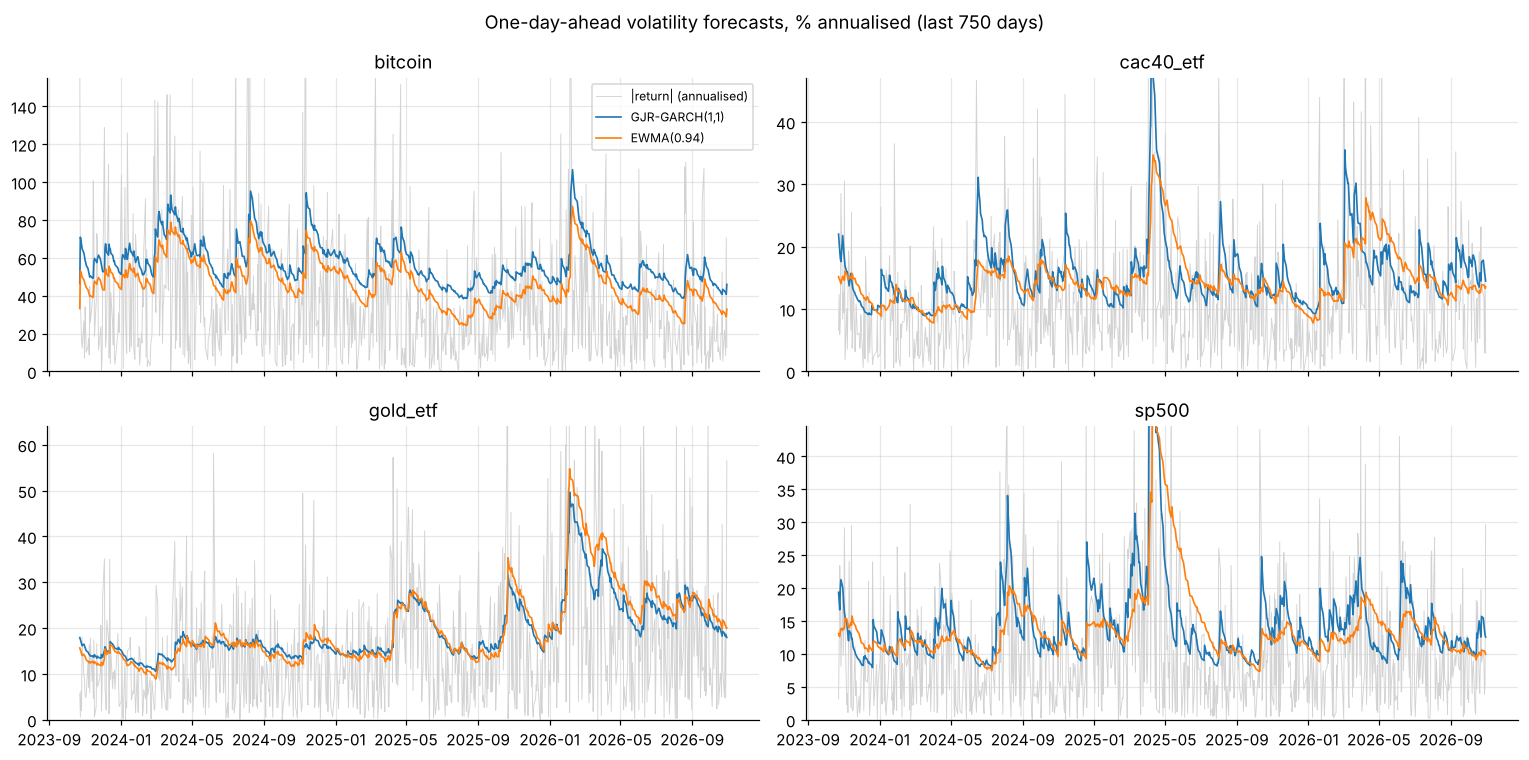

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
for ax, c in zip(axes.ravel(), r):
    f = fcs[c]
    ax.plot(f.index, np.sqrt(f["realized"] * 252), c="lightgrey", lw=.6, label="|return| (annualised)")
    for m in ["GJR-GARCH(1,1)", "EWMA(0.94)"]:
        ax.plot(f.index, np.sqrt(f[m] * 252), lw=1.1, label=m)
    ax.set_title(c); ax.set_ylim(0, np.percentile(np.sqrt(f["realized"] * 252), 99))
axes[0, 0].legend(fontsize=8); fig.suptitle("One-day-ahead volatility forecasts, % annualised (last 750 days)")
plt.tight_layout(); plt.savefig(FIG / "03_vol_forecasts.png", bbox_inches="tight"); plt.show()

## Findings
* **Leverage matters for equities, not for gold or Bitcoin.** The GJR asymmetry term is 0.20 for the CAC 40 ETF and 0.25 for the S&P 500, so falling markets raise volatility much more than rising ones. For gold and Bitcoin the term is close to zero.
* Bitcoin's GARCH(1,1) persistence is about 1.00 (integrated variance) and its Student-t degrees of freedom are about 3, i.e. very heavy tails.
* **In-sample and out-of-sample winners differ.** BIC picks EGARCH for three of the four assets. Over the last 750 days, GJR-GARCH has the lowest QLIKE for gold and the S&P 500, EGARCH for the CAC 40, and plain RiskMetrics EWMA beats every GARCH model for Bitcoin.
* Every model except EGARCH on Bitcoin beats the 60-day rolling variance, a benchmark that is still widely used.